# Screening Benchmark Results Analysis

This notebook analyzes the benchmark outputs in:

`/SR-agents/bastirr/output/screening_benchmarks/20260512_122615_screening_ladder_dev_exclude_balanced/include_policy`

Active gold-label policy: `include_label_0_5`

It stays fully within this policy folder and focuses on:

1. Run health, class balance, and runtime scaling
2. Metric stability across repeats
3. Review-level performance patterns
4. Confusion matrices under the active policy
5. Error composition and pass-count calibration
6. Study-level stability and recurring hard cases


In [1]:
from pathlib import Path
import json
import os
import warnings

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
warnings.filterwarnings("ignore", message="Pandas requires version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

plt.style.use("ggplot")
plt.rcParams.update({
    "figure.figsize": (12, 7),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "font.size": 10,
})

POLICY_RELATIVE_PATH = Path("bastirr/output/screening_benchmarks/20260512_122615_screening_ladder_dev_exclude_balanced/include_policy")
POLICY_DISPLAY_PATH = Path("/SR-agents") / POLICY_RELATIVE_PATH

def resolve_policy_dir():
    cwd = Path.cwd().resolve()
    if (cwd / "summary.csv").exists() and (cwd / "summary.json").exists():
        return cwd
    for base in [cwd, *cwd.parents]:
        if base.name == "SR-agents":
            candidate = base / POLICY_RELATIVE_PATH
            if candidate.exists():
                return candidate
        repo_child = base / "SR-agents"
        candidate = repo_child / POLICY_RELATIVE_PATH
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not resolve benchmark policy directory for {POLICY_DISPLAY_PATH}"
    )

def to_display_path(raw_path):
    if raw_path is None or (isinstance(raw_path, float) and pd.isna(raw_path)):
        return ""
    path = Path(str(raw_path)).expanduser()
    if not path.is_absolute():
        return str(path)
    for candidate in (path, *path.parents):
        if candidate.name == "SR-agents":
            try:
                return str(Path("/SR-agents") / path.relative_to(candidate))
            except ValueError:
                break
    return str(path)

POLICY_DIR = resolve_policy_dir()
SUMMARY_CSV = POLICY_DIR / "summary.csv"
SUMMARY_JSON = POLICY_DIR / "summary.json"

summary_df = pd.read_csv(SUMMARY_CSV)
summary_payload = json.loads(SUMMARY_JSON.read_text())
review_leaderboard_df = pd.DataFrame(summary_payload.get("review_leaderboard", []))

bool_columns = ["parse_success", "scored_for_aggregate", "rerun_triggered"]
for column in bool_columns:
    if column in summary_df.columns:
        summary_df[column] = (
            summary_df[column]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"true": True, "false": False})
            .fillna(summary_df[column])
        )

numeric_columns = [
    "n_studies",
    "gold_pass_count",
    "gold_exclude_count",
    "predicted_pass_count",
    "predicted_exclude_count",
    "screening_decision_count",
    "missing_decision_count",
    "duplicate_decision_count",
    "invalid_decision_count",
    "decision_coverage",
    "tp",
    "fp",
    "tn",
    "fn",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "duration_seconds",
    "screening_attempt_count",
    "run_index",
]
for column in numeric_columns:
    if column in summary_df.columns:
        summary_df[column] = pd.to_numeric(summary_df[column], errors="coerce")
    if column in review_leaderboard_df.columns:
        review_leaderboard_df[column] = pd.to_numeric(review_leaderboard_df[column], errors="coerce")

review_meta = (
    summary_df[["review_key", "review_title", "n_studies", "gold_pass_count", "gold_exclude_count"]]
    .drop_duplicates()
    .sort_values(["n_studies", "review_key"])
    .reset_index(drop=True)
)
review_order = review_meta["review_key"].tolist()
review_label_map = {
    row.review_key: f"{row.review_key} (n={int(row.n_studies)})"
    for row in review_meta.itertuples()
}

def short_review_label(review_key: str) -> str:
    return review_label_map.get(review_key, review_key.replace("_", " "))

scored_runs_df = summary_df.loc[summary_df["scored_for_aggregate"] == True].copy()

def normalize_predicted_decision(value):
    if value is None:
        return ""
    text = str(value).strip().upper()
    if text == "INCLUDE":
        return "INCLUDE"
    if text == "EXCLUDE":
        return "EXCLUDE"
    if "INCLUDE" in text and "EXCLUDE" not in text:
        return "INCLUDE"
    if "EXCLUDE" in text and "INCLUDE" not in text:
        return "EXCLUDE"
    return ""

inspection_rows = []
for row in summary_df.itertuples():
    inspection_path = Path(row.screening_inspection_json)
    if not inspection_path.exists():
        continue
    payload = json.loads(inspection_path.read_text())
    for study in payload.get("studies", []):
        predicted_decision = normalize_predicted_decision(study.get("predicted_decision"))
        gold_decision = str(study.get("gold_screening_decision") or "").strip().upper()
        inspection_rows.append({
            "benchmark_run_id": row.benchmark_run_id,
            "review_key": row.review_key,
            "review_title": row.review_title,
            "run_index": row.run_index,
            "scored_for_aggregate": bool(row.scored_for_aggregate),
            "study_index": study.get("study_index"),
            "study_title": study.get("study_title"),
            "gold_label": study.get("gold_label"),
            "gold_screening_decision": gold_decision,
            "gold_review_outcome": study.get("gold_review_outcome"),
            "predicted_decision": predicted_decision,
            "predicted_reason": study.get("predicted_reason"),
        })

study_df = pd.DataFrame(inspection_rows)
if not study_df.empty:
    study_df["gold_is_include"] = study_df["gold_screening_decision"] == "INCLUDE"
    study_df["pred_is_include"] = study_df["predicted_decision"] == "INCLUDE"
    study_df["pred_is_exclude"] = study_df["predicted_decision"] == "EXCLUDE"
    study_df["tp"] = (study_df["gold_is_include"] & study_df["pred_is_include"]).astype(int)
    study_df["fn"] = (study_df["gold_is_include"] & study_df["pred_is_exclude"]).astype(int)
    study_df["fp"] = ((~study_df["gold_is_include"]) & study_df["pred_is_include"]).astype(int)
    study_df["tn"] = ((~study_df["gold_is_include"]) & study_df["pred_is_exclude"]).astype(int)
scored_study_df = study_df.loc[study_df["scored_for_aggregate"] == True].copy() if not study_df.empty else study_df.copy()

def summarize_confusion(frame):
    if frame.empty:
        return {
            "tp": 0,
            "fp": 0,
            "tn": 0,
            "fn": 0,
            "accuracy": float("nan"),
            "precision": float("nan"),
            "recall": float("nan"),
            "specificity": float("nan"),
            "f1": float("nan"),
            "total": 0,
        }
    tp = int(frame["tp"].sum())
    fp = int(frame["fp"].sum())
    tn = int(frame["tn"].sum())
    fn = int(frame["fn"].sum())
    total = tp + fp + tn + fn
    accuracy = (tp + tn) / total if total else float("nan")
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    specificity = tn / (tn + fp) if (tn + fp) else float("nan")
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else float("nan")
    return {
        "tp": tp,
        "fp": fp,
        "tn": tn,
        "fn": fn,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "total": total,
    }

def plot_confusion(ax, stats, title):
    matrix = np.array([
        [stats["tp"], stats["fn"]],
        [stats["fp"], stats["tn"]],
    ], dtype=float)
    total = stats["total"] if stats["total"] else 1
    im = ax.imshow(matrix, cmap="Blues", interpolation="nearest")
    threshold = matrix.max() / 2 if matrix.size else 0
    ax.set_title(title)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred INCLUDE", "Pred EXCLUDE"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Gold INCLUDE", "Gold EXCLUDE"])
    ax.grid(False)
    ax.tick_params(axis="y", pad=6)
    for i in range(2):
        for j in range(2):
            value = int(matrix[i, j])
            pct = 100 * matrix[i, j] / total
            text_color = "white" if matrix[i, j] >= threshold else "#1f2937"
            ax.text(j, i, f"{value}\n{pct:.1f}%", ha="center", va="center", color=text_color, fontweight="bold")
    return im

print("Policy directory:", POLICY_DISPLAY_PATH)
print("Suite:", summary_payload.get("suite"))
print("Policy:", summary_payload.get("gold_label_policy"))
print("Repeats:", summary_payload.get("repeats"))
print("Runs:", len(summary_df))
print("Scored runs:", int(scored_runs_df.shape[0]))
print("Scored study decisions:", int(scored_study_df.shape[0]))


Policy directory: /SR-agents/bastirr/output/screening_benchmarks/20260512_122615_screening_ladder_dev_exclude_balanced/include_policy
Suite: screening_ladder_dev_exclude_balanced
Policy: include_label_0_5
Repeats: 1
Runs: 5
Scored runs: 5
Scored study decisions: 379


## 1. Run Overview

Start by separating benchmark health from model quality. This view shows run completeness, dataset class balance, and runtime scaling.

,suite,policy,repeats,total_runs,completed_runs,incomplete_runs,error_runs,scored_runs,parse_success_rate_all_runs,mean_missing_decisions_all_runs,runs_with_reruns,macro_accuracy_scored_runs,macro_precision_scored_runs,macro_recall_scored_runs,macro_f1_scored_runs
0,screening_ladder_dev_exclude_balanced,include_label_0_5,1,5,5,0,0,5,1.0,0.0,1,0.832,0.993,0.746,0.849


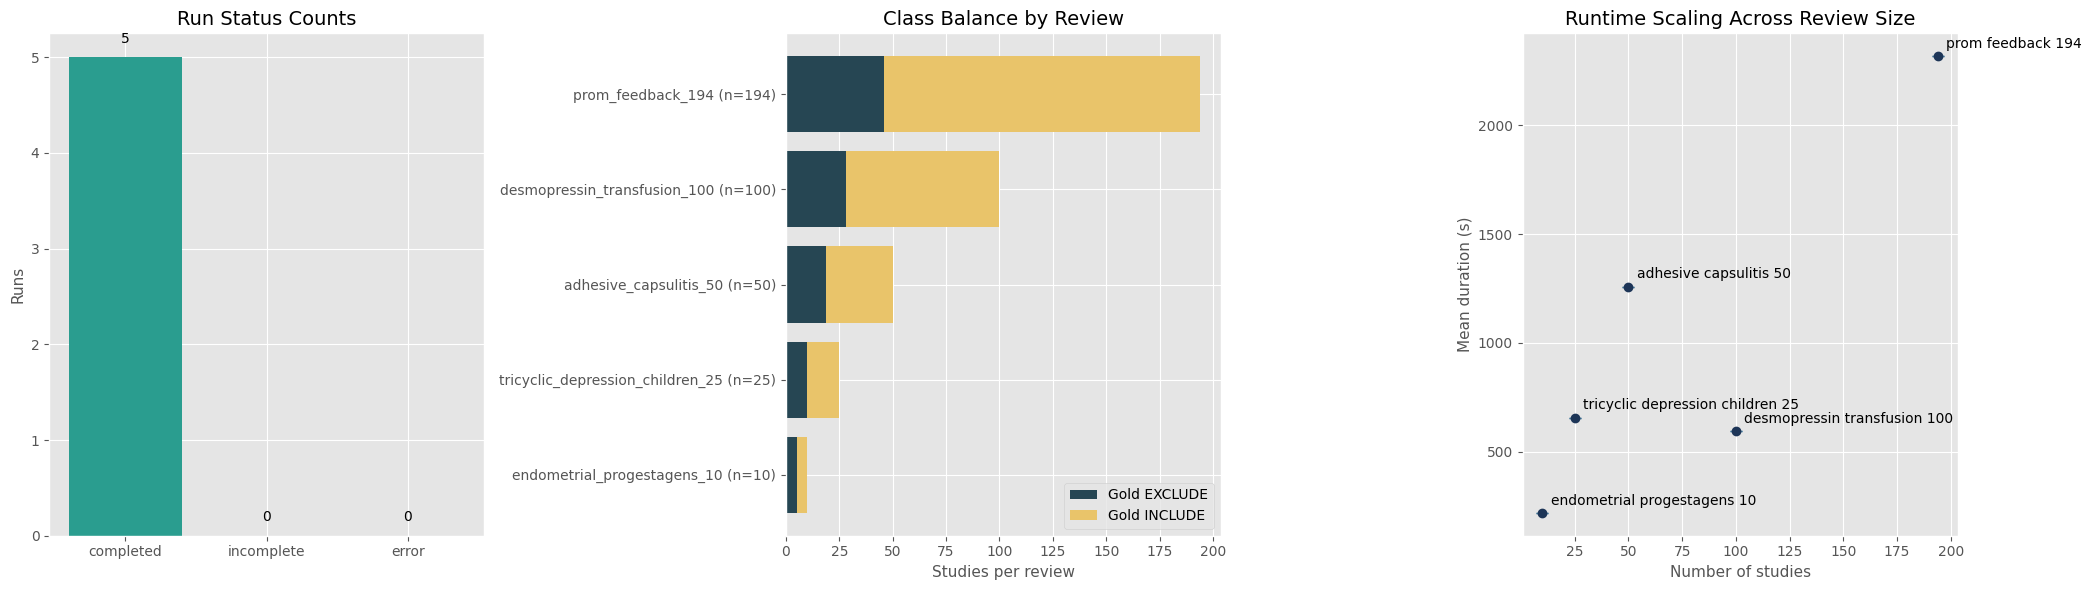

No incomplete or unscored runs were recorded in this policy view.

In [2]:
run_overview = pd.DataFrame([{
    "suite": summary_payload.get("suite"),
    "policy": summary_payload.get("gold_label_policy"),
    "repeats": summary_payload.get("repeats"),
    "total_runs": len(summary_df),
    "completed_runs": int((summary_df["run_status"] == "completed").sum()),
    "incomplete_runs": int((summary_df["run_status"] == "incomplete").sum()),
    "error_runs": int((summary_df["run_status"] == "error").sum()),
    "scored_runs": int(summary_df["scored_for_aggregate"].fillna(False).sum()),
    "parse_success_rate_all_runs": summary_df["parse_success"].astype(float).mean(),
    "mean_missing_decisions_all_runs": summary_df["missing_decision_count"].mean(),
    "runs_with_reruns": int(summary_df["rerun_triggered"].fillna(False).sum()),
    "macro_accuracy_scored_runs": scored_runs_df["accuracy"].mean(),
    "macro_precision_scored_runs": scored_runs_df["precision"].mean(),
    "macro_recall_scored_runs": scored_runs_df["recall"].mean(),
    "macro_f1_scored_runs": scored_runs_df["f1"].mean(),
}])
display(run_overview.round(3))

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

status_counts = (
    summary_df["run_status"]
    .value_counts()
    .reindex(["completed", "incomplete", "error"])
    .fillna(0)
)
axes[0].bar(status_counts.index, status_counts.values, color=["#2a9d8f", "#e76f51", "#9d4edd"])
axes[0].set_title("Run Status Counts")
axes[0].set_ylabel("Runs")
for i, value in enumerate(status_counts.values):
    axes[0].text(i, value + 0.15, int(value), ha="center")

class_balance_df = review_meta.set_index("review_key").loc[review_order, ["gold_exclude_count", "gold_pass_count"]]
axes[1].barh(
    [short_review_label(review_key) for review_key in review_order],
    class_balance_df["gold_exclude_count"],
    color="#264653",
    label="Gold EXCLUDE",
)
axes[1].barh(
    [short_review_label(review_key) for review_key in review_order],
    class_balance_df["gold_pass_count"],
    left=class_balance_df["gold_exclude_count"],
    color="#e9c46a",
    label="Gold INCLUDE",
)
axes[1].set_title("Class Balance by Review")
axes[1].set_xlabel("Studies per review")
axes[1].legend(loc="lower right")

runtime_summary = (
    summary_df.groupby("review_key")
    .agg(
        n_studies=("n_studies", "first"),
        mean_duration=("duration_seconds", "mean"),
        std_duration=("duration_seconds", "std"),
    )
    .loc[review_order]
    .reset_index()
)
axes[2].errorbar(
    runtime_summary["n_studies"],
    runtime_summary["mean_duration"],
    yerr=runtime_summary["std_duration"].fillna(0),
    fmt="o",
    color="#1d3557",
    ecolor="#457b9d",
    capsize=4,
)
for row in runtime_summary.itertuples():
    axes[2].annotate(
        row.review_key.replace("_", " "),
        (row.n_studies, row.mean_duration),
        xytext=(6, 6),
        textcoords="offset points",
    )
axes[2].set_title("Runtime Scaling Across Review Size")
axes[2].set_xlabel("Number of studies")
axes[2].set_ylabel("Mean duration (s)")

plt.tight_layout()
plt.show()

incomplete_runs_df = summary_df.loc[summary_df["scored_for_aggregate"] != True].copy()
if incomplete_runs_df.empty:
    display(Markdown("No incomplete or unscored runs were recorded in this policy view."))
else:
    incomplete_runs_df["run_path"] = incomplete_runs_df["run_dir"].map(to_display_path)
    display(
        incomplete_runs_df[
            [
                "benchmark_run_id",
                "review_key",
                "run_status",
                "screening_completion_status",
                "screening_attempt_count",
                "rerun_triggered",
                "screening_decision_count",
                "missing_decision_count",
                "invalid_decision_count",
                "decision_coverage",
                "incomplete_reason",
                "run_path",
            ]
        ]
        .reset_index(drop=True)
    )


## 2. Metric Stability Across Repeats

The box plots show how much the policy-local metrics move across repeated runs.

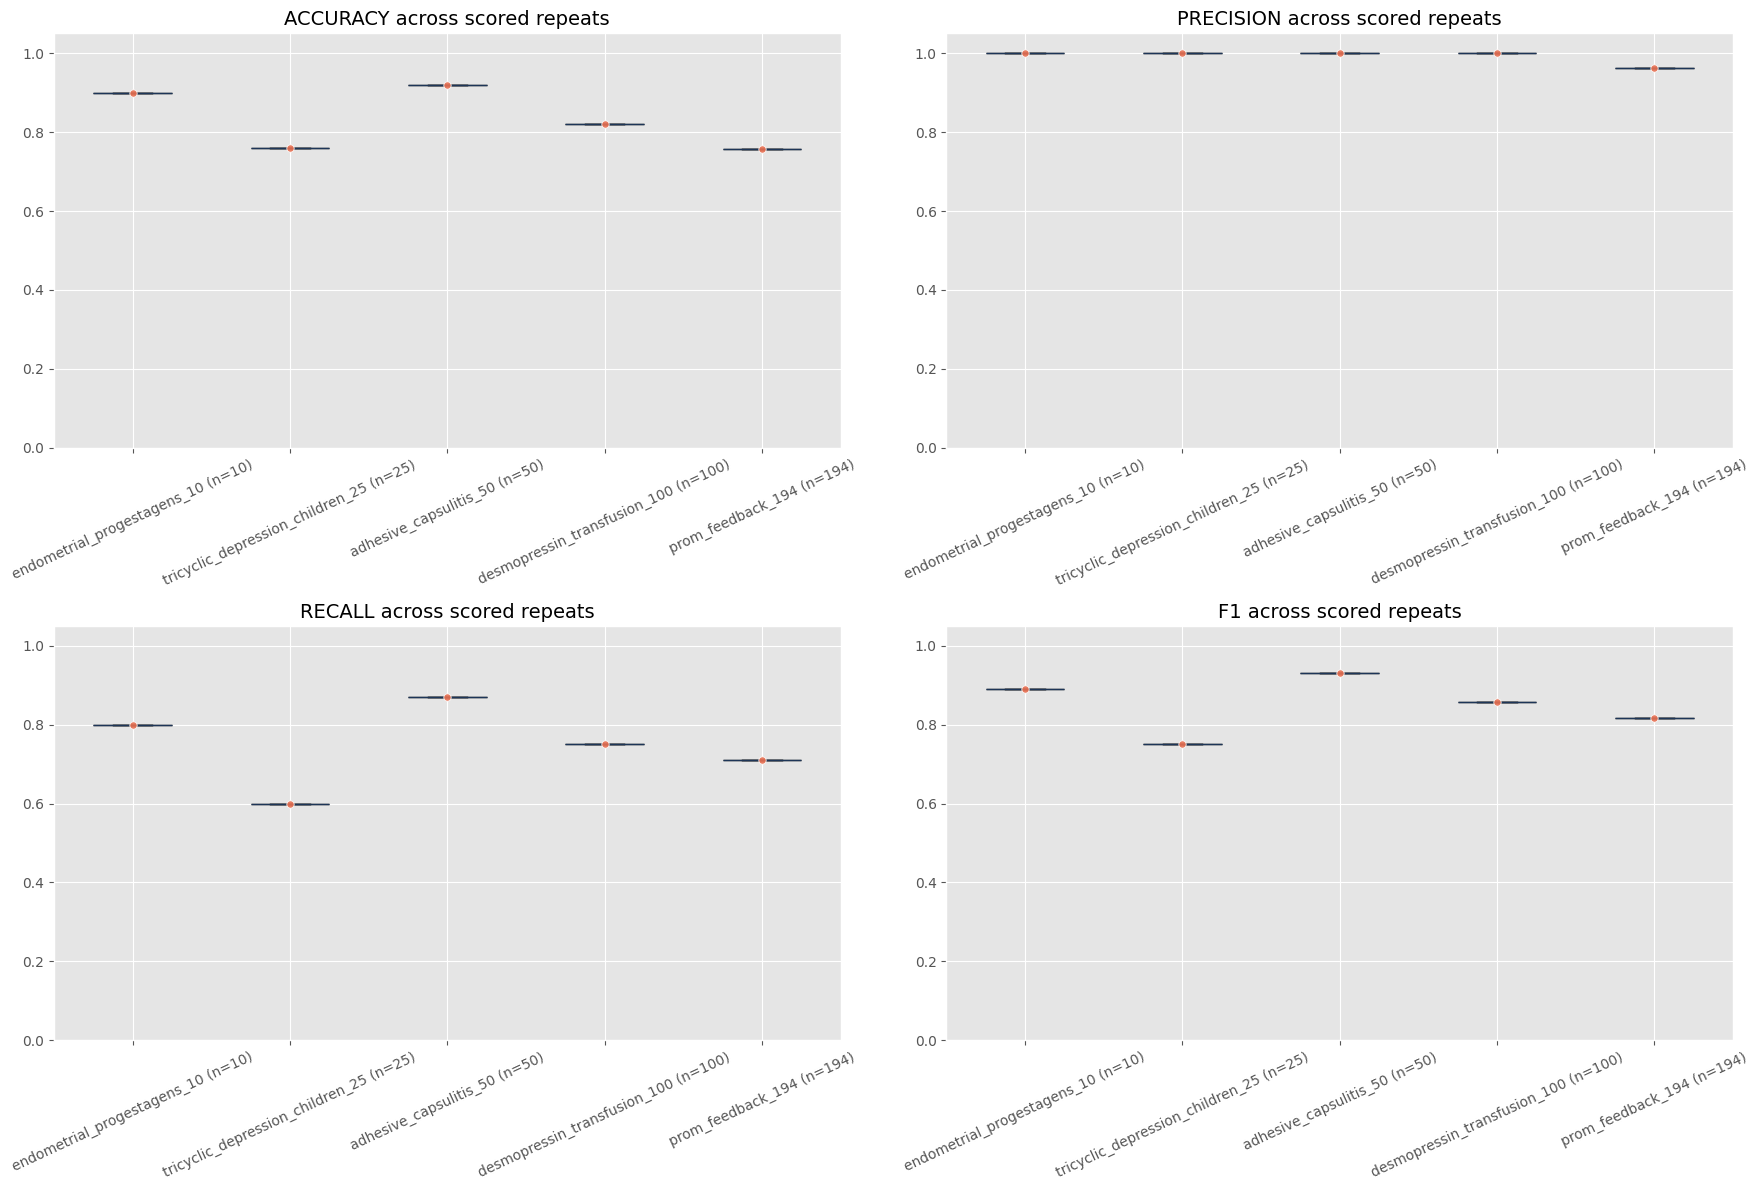

In [3]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1"]
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for ax, metric in zip(axes, metrics_to_plot):
    series = [
        scored_runs_df.loc[scored_runs_df["review_key"] == review_key, metric].dropna().values
        for review_key in review_order
    ]
    bp = ax.boxplot(
        series,
        tick_labels=[short_review_label(review_key) for review_key in review_order],
        patch_artist=True,
        boxprops=dict(facecolor="#bde0fe", alpha=0.85),
        medianprops=dict(color="#1d3557"),
    )
    for artist_group in bp.values():
        if isinstance(artist_group, list):
            for artist in artist_group:
                artist.set_zorder(1)
        else:
            artist_group.set_zorder(1)
    for i, values in enumerate(series, start=1):
        if len(values):
            ax.scatter(
                [i] * len(values),
                values,
                color="#e76f51",
                edgecolors="white",
                linewidths=0.6,
                alpha=0.9,
                s=28,
                zorder=4,
            )
    ax.set_title(f"{metric.upper()} across scored repeats")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


## 3. Review-Level Performance Patterns

This section summarizes the review-level means that drive the leaderboard and highlights where performance drops off.

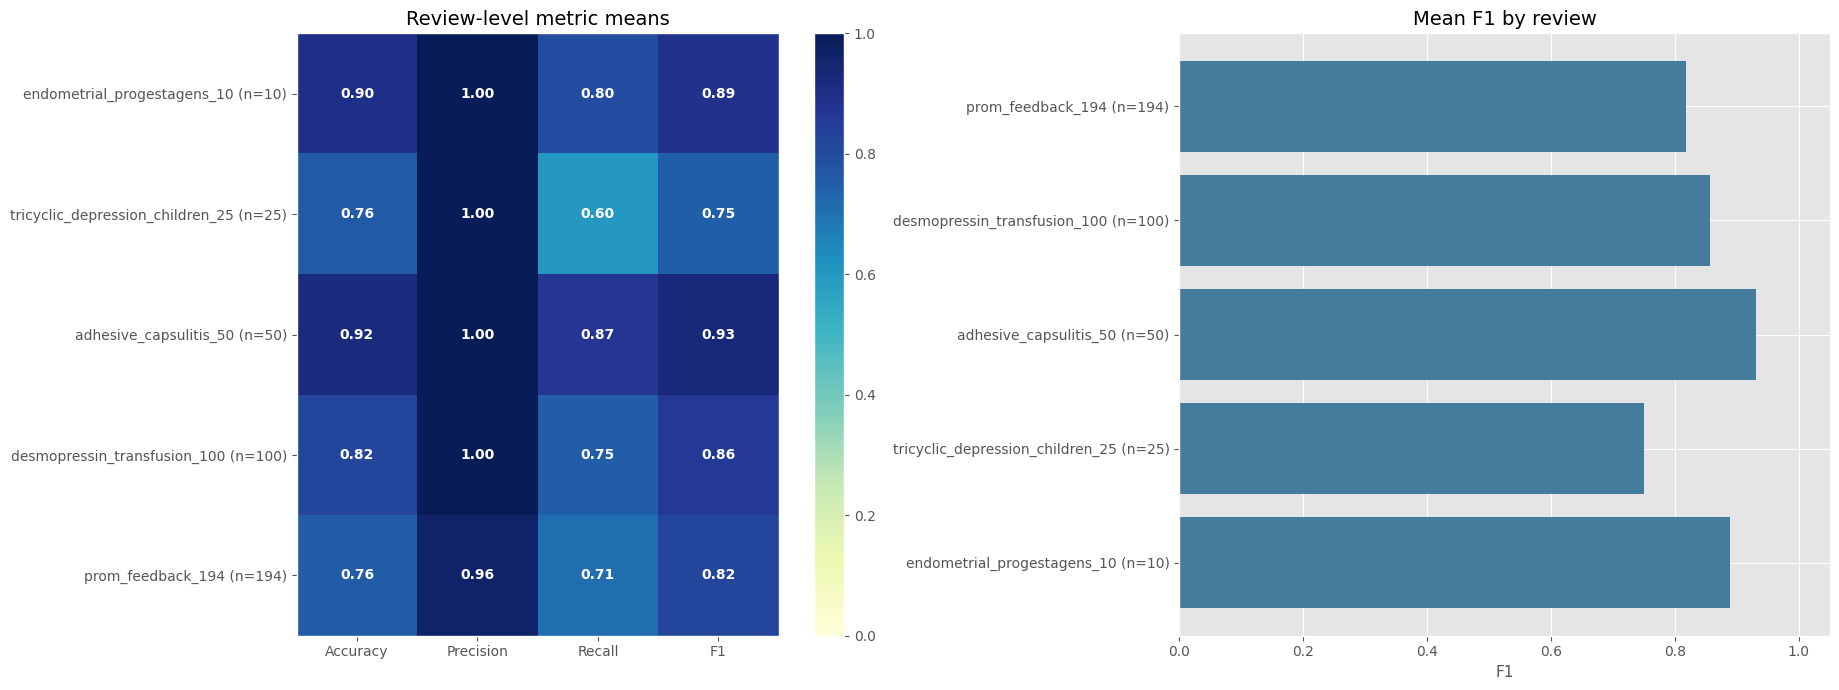

,review,studies,gold_include,gold_exclude,runs,scored,incomplete,accuracy,precision,recall,f1
0,endometrial_progestagens_10,10,5,5,1,1,0,0.900,1.000,0.800,0.889
1,tricyclic_depression_children_25,25,15,10,1,1,0,0.760,1.000,0.600,0.750
2,adhesive_capsulitis_50,50,31,19,1,1,0,0.920,1.000,0.871,0.931
3,desmopressin_transfusion_100,100,72,28,1,1,0,0.820,1.000,0.750,0.857
4,prom_feedback_194,194,148,46,1,1,0,0.758,0.963,0.709,0.817


In [4]:
review_metric_columns = [
    column
    for column in review_leaderboard_df.columns
    if column not in {"n_studies", "gold_pass_count", "gold_exclude_count", "review_title"}
]
review_display_df = review_meta.merge(
    review_leaderboard_df[review_metric_columns],
    on="review_key",
    how="left",
)

heatmap_df = (
    review_display_df
    .set_index("review_key")[["mean_accuracy", "mean_precision", "mean_recall", "mean_f1"]]
    .reindex(review_order)
)
f1_series = review_display_df.set_index("review_key").reindex(review_order)["mean_f1"]

fig, axes = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={"width_ratios": [1.15, 0.85]})
im = axes[0].imshow(heatmap_df.values, cmap="YlGnBu", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_xticks(range(len(heatmap_df.columns)))
axes[0].set_xticklabels(["Accuracy", "Precision", "Recall", "F1"])
axes[0].set_yticks(range(len(review_order)))
axes[0].set_yticklabels([short_review_label(review_key) for review_key in review_order])
axes[0].set_title("Review-level metric means")
axes[0].grid(False)
threshold = np.nanmax(heatmap_df.values) / 2 if heatmap_df.size else 0
for i in range(len(review_order)):
    for j in range(len(heatmap_df.columns)):
        value = heatmap_df.iloc[i, j]
        if pd.notna(value):
            text_color = "white" if value >= threshold else "#1f2937"
            axes[0].text(j, i, f"{value:.2f}", ha="center", va="center", color=text_color, fontweight="bold")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].barh(
    [short_review_label(review_key) for review_key in review_order],
    f1_series.values,
    color="#457b9d",
)
axes[1].set_xlim(0, 1.05)
axes[1].set_title("Mean F1 by review")
axes[1].set_xlabel("F1")

plt.tight_layout()
plt.show()

table_df = (
    review_display_df[
        [
            "review_key",
            "n_studies",
            "gold_pass_count",
            "gold_exclude_count",
            "n_runs",
            "n_scored_runs",
            "n_incomplete_runs",
            "mean_accuracy",
            "mean_precision",
            "mean_recall",
            "mean_f1",
        ]
    ]
    .rename(
        columns={
            "review_key": "review",
            "n_studies": "studies",
            "gold_pass_count": "gold_include",
            "gold_exclude_count": "gold_exclude",
            "n_runs": "runs",
            "n_scored_runs": "scored",
            "n_incomplete_runs": "incomplete",
            "mean_accuracy": "accuracy",
            "mean_precision": "precision",
            "mean_recall": "recall",
            "mean_f1": "f1",
        }
    )
    .sort_values(["studies", "review"])
    .reset_index(drop=True)
)
display(table_df.round(3))


## 4. Confusion Matrices Under The Active Policy

These confusion matrices use the currently active gold-label policy and aggregate across the scored runs only.

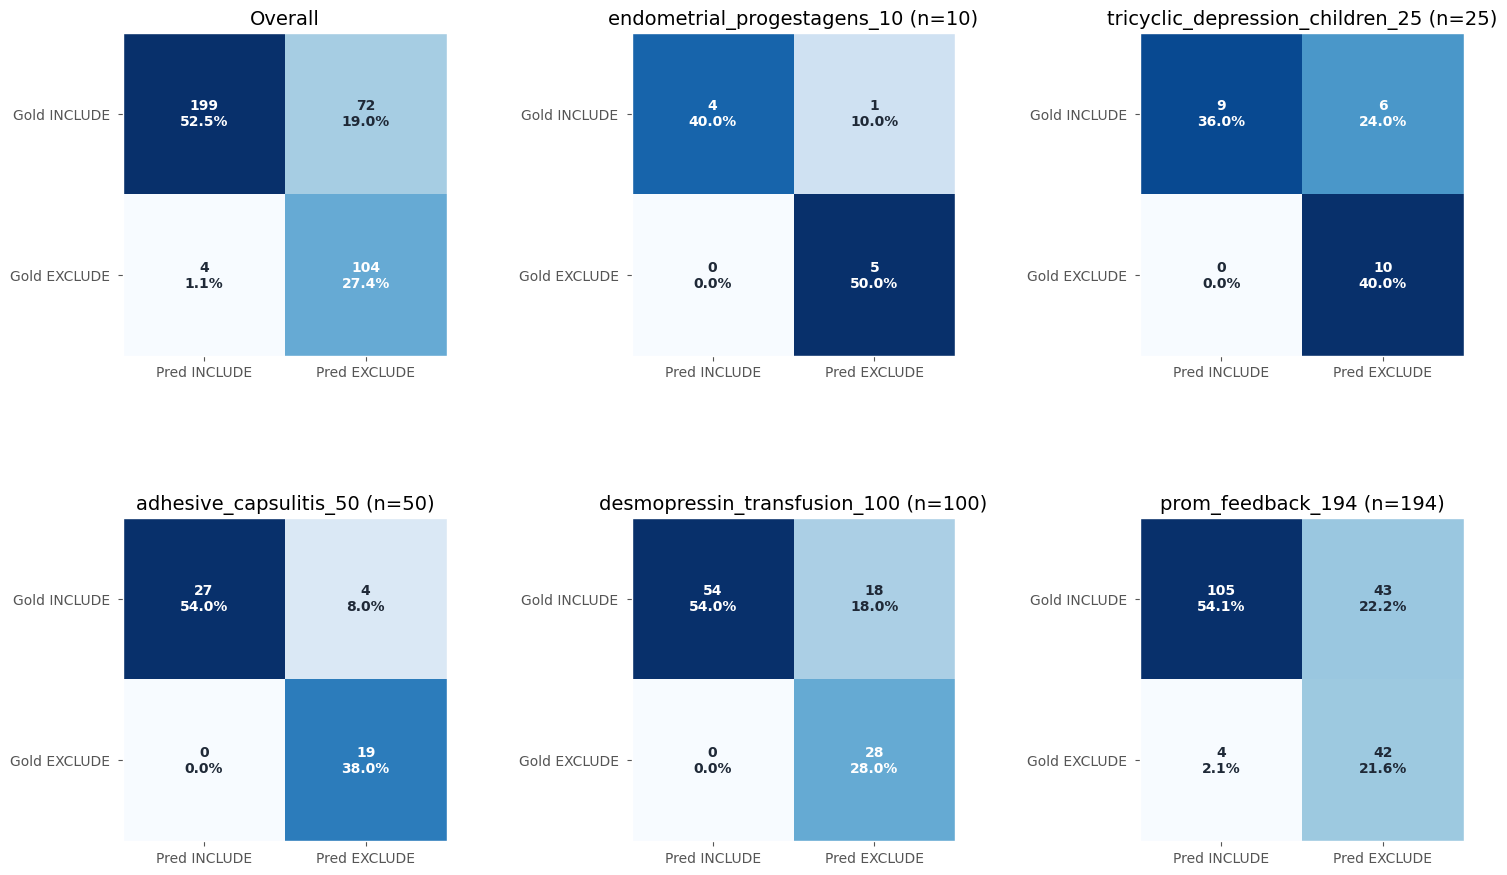

,scope,tp,fp,tn,fn,accuracy,precision,recall,specificity,f1
0,overall,199,4,104,72,0.799,0.980,0.734,0.963,0.840
1,endometrial_progestagens_10,4,0,5,1,0.900,1.000,0.800,1.000,0.889
2,tricyclic_depression_children_25,9,0,10,6,0.760,1.000,0.600,1.000,0.750
3,adhesive_capsulitis_50,27,0,19,4,0.920,1.000,0.871,1.000,0.931
4,desmopressin_transfusion_100,54,0,28,18,0.820,1.000,0.750,1.000,0.857
5,prom_feedback_194,105,4,42,43,0.758,0.963,0.709,0.913,0.817


In [5]:
overall_stats = summarize_confusion(scored_study_df)
by_review = {
    review_key: summarize_confusion(group)
    for review_key, group in scored_study_df.groupby("review_key")
}

fig, axes = plt.subplots(2, 3, figsize=(17.5, 10.5))
axes = axes.flatten()
plot_confusion(axes[0], overall_stats, "Overall")
for ax, review_key in zip(axes[1:], review_order):
    plot_confusion(ax, by_review.get(review_key, summarize_confusion(scored_study_df.iloc[0:0])), short_review_label(review_key))
for ax in axes[len(review_order) + 1:]:
    ax.axis("off")
fig.subplots_adjust(wspace=0.50, hspace=0.50)
plt.show()

confusion_summary_df = pd.DataFrame(
    [
        {
            "scope": "overall",
            **overall_stats,
        },
        *[
            {
                "scope": review_key,
                **by_review[review_key],
            }
            for review_key in review_order
        ],
    ]
)
display(
    confusion_summary_df[
        ["scope", "tp", "fp", "tn", "fn", "accuracy", "precision", "recall", "specificity", "f1"]
    ].round(3)
)


## 5. Error Composition And Pass-Count Calibration

These views show whether misses cluster in specific review-outcome categories and whether the model is conservative or permissive at the pass-count level.

,gold_label,gold_review_outcome,errors
1,0.5,excluded_after_full_text,57
2,1.0,included_in_review,15
0,0.0,excluded_at_screening,4


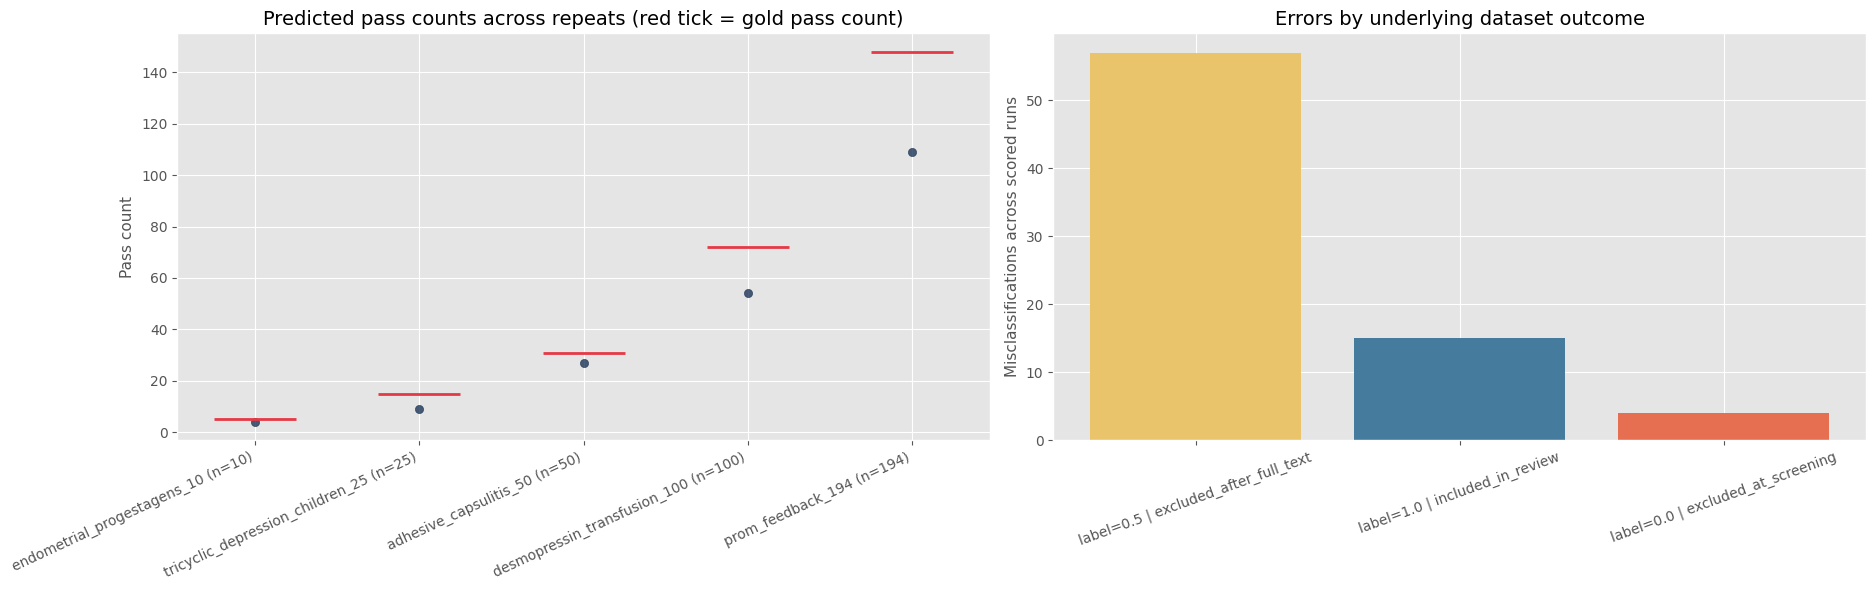

In [6]:
error_study_df = scored_study_df.loc[(scored_study_df["fp"] == 1) | (scored_study_df["fn"] == 1)].copy()

fig, axes = plt.subplots(1, 2, figsize=(19, 6))

for i, review_key in enumerate(review_order):
    subset = summary_df.loc[summary_df["review_key"] == review_key].sort_values("run_index")
    axes[0].scatter(
        [i] * len(subset),
        subset["predicted_pass_count"],
        color="#1d3557",
        alpha=0.8,
        s=35,
    )
    if not subset.empty:
        gold_value = subset["gold_pass_count"].iloc[0]
        axes[0].hlines(gold_value, i - 0.25, i + 0.25, color="#e63946", linewidth=2)
axes[0].set_xticks(range(len(review_order)))
axes[0].set_xticklabels([short_review_label(review_key) for review_key in review_order], rotation=25, ha="right")
axes[0].set_ylabel("Pass count")
axes[0].set_title("Predicted pass counts across repeats (red tick = gold pass count)")

if error_study_df.empty:
    axes[1].axis("off")
    display(Markdown("No misclassifications were found in scored runs under this policy."))
else:
    error_breakdown = (
        error_study_df.groupby(["gold_label", "gold_review_outcome"])
        .size()
        .reset_index(name="errors")
        .sort_values("errors", ascending=False)
    )
    labels = [
        f"label={row.gold_label} | {row.gold_review_outcome}"
        for row in error_breakdown.itertuples()
    ]
    color_map = ["#e9c46a", "#457b9d", "#e76f51", "#6c757d"]
    axes[1].bar(labels, error_breakdown["errors"], color=color_map[: len(labels)])
    axes[1].set_title("Errors by underlying dataset outcome")
    axes[1].set_ylabel("Misclassifications across scored runs")
    axes[1].tick_params(axis="x", rotation=20)
    display(error_breakdown)

plt.tight_layout()
plt.show()


## 6. Study-Level Stability And Recurring Hard Cases

Aggregate metrics tell us how much error there is. This section shows where the recurring instability lives.

,n_studies,perfectly_classified,unstable,never_correct,perfect_share
review_key,,,,,
endometrial_progestagens_10,10,9,0,1,0.900
tricyclic_depression_children_25,25,19,0,6,0.760
adhesive_capsulitis_50,50,46,0,4,0.920
desmopressin_transfusion_100,100,82,0,18,0.820
prom_feedback_194,194,147,0,47,0.758


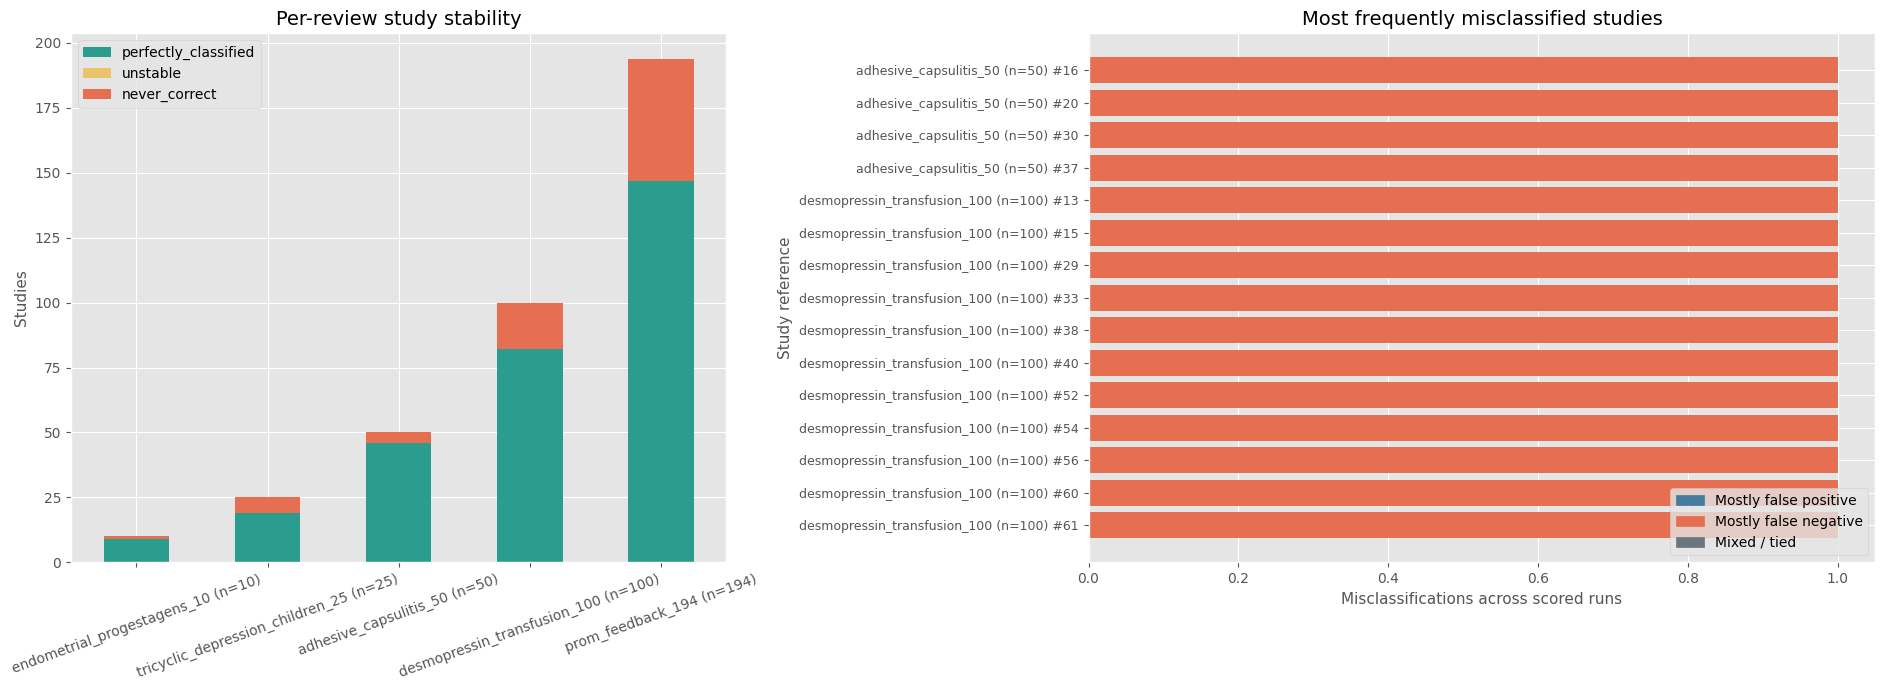

,study_ref,study_title,mistake_count,dominant_error,gold_label,gold_review_outcome
0,adhesive_capsulitis_50 (n=50) #16,A study on the clinical effects of physical th...,1,false_negative,1.0,included_in_review
1,adhesive_capsulitis_50 (n=50) #20,Effects of deep and superficial heating in the...,1,false_negative,0.5,excluded_after_full_text
2,adhesive_capsulitis_50 (n=50) #30,Relief of chronic shoulder pain: a comparative...,1,false_negative,0.5,excluded_after_full_text
3,adhesive_capsulitis_50 (n=50) #37,Effects of iontophoresis and phonophoresis met...,1,false_negative,0.5,excluded_after_full_text
4,desmopressin_transfusion_100 (n=100) #13,Intranasal desmopressin versus blood transfusi...,1,false_negative,0.5,excluded_after_full_text
5,desmopressin_transfusion_100 (n=100) #15,Use of desmopressin to prevent bleeding compli...,1,false_negative,0.5,excluded_after_full_text
6,desmopressin_transfusion_100 (n=100) #29,Desmopressin (DDAVP) in lumbar puncture,1,false_negative,0.5,excluded_after_full_text
7,desmopressin_transfusion_100 (n=100) #33,Venous thrombosis following diagnostic transve...,1,false_negative,0.5,excluded_after_full_text
8,desmopressin_transfusion_100 (n=100) #38,Use of desmopressin acetate to reduce blood tr...,1,false_negative,1.0,included_in_review
9,desmopressin_transfusion_100 (n=100) #40,Biopsy: desmopressin reduces risk of bleeding ...,1,false_negative,0.5,excluded_after_full_text


In [7]:
if scored_study_df.empty:
    display(Markdown("No scored study-level rows were available for stability analysis."))
else:
    study_stability = (
        scored_study_df.groupby(
            ["review_key", "study_index", "study_title", "gold_label", "gold_review_outcome"]
        )
        .agg(
            n_runs=("benchmark_run_id", "count"),
            tp=("tp", "sum"),
            fp=("fp", "sum"),
            tn=("tn", "sum"),
            fn=("fn", "sum"),
            include_rate=("predicted_decision", lambda s: (s == "INCLUDE").mean()),
        )
        .reset_index()
    )
    study_stability["n_correct"] = study_stability["tp"] + study_stability["tn"]
    study_stability["accuracy"] = study_stability["n_correct"] / study_stability["n_runs"]
    study_stability["mistake_count"] = study_stability["fp"] + study_stability["fn"]
    study_stability["dominant_error"] = np.select(
        [
            study_stability["fp"] > study_stability["fn"],
            study_stability["fn"] > study_stability["fp"],
        ],
        ["false_positive", "false_negative"],
        default="mixed_or_none",
    )

    review_consistency = (
        study_stability.groupby("review_key")["accuracy"]
        .agg(
            n_studies="count",
            perfectly_classified=lambda s: int((s == 1.0).sum()),
            unstable=lambda s: int(((s > 0.0) & (s < 1.0)).sum()),
            never_correct=lambda s: int((s == 0.0).sum()),
        )
        .loc[review_order]
    )
    review_consistency["perfect_share"] = (
        review_consistency["perfectly_classified"] / review_consistency["n_studies"]
    ).round(3)
    display(review_consistency)

    fig, axes = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={"width_ratios": [1.0, 1.2]})
    consistency_plot = review_consistency[["perfectly_classified", "unstable", "never_correct"]].copy()
    consistency_plot.index = [short_review_label(r) for r in consistency_plot.index]
    consistency_plot.plot(
        kind="bar",
        stacked=True,
        ax=axes[0],
        color=["#2a9d8f", "#e9c46a", "#e76f51"],
    )
    axes[0].set_title("Per-review study stability")
    axes[0].set_ylabel("Studies")
    axes[0].tick_params(axis="x", rotation=20)

    worst_studies = (
        study_stability.sort_values(["mistake_count", "accuracy"], ascending=[False, True])
        .head(15)
        .copy()
    )
    worst_studies["study_ref"] = worst_studies.apply(
        lambda row: f"{short_review_label(row['review_key'])} #{int(row['study_index'])}",
        axis=1,
    )
    colors = worst_studies["dominant_error"].map(
        {
            "false_positive": "#457b9d",
            "false_negative": "#e76f51",
            "mixed_or_none": "#6c757d",
        }
    )
    axes[1].barh(worst_studies["study_ref"], worst_studies["mistake_count"], color=colors)
    axes[1].invert_yaxis()
    axes[1].set_title("Most frequently misclassified studies")
    axes[1].set_xlabel("Misclassifications across scored runs")
    axes[1].set_ylabel("Study reference")
    axes[1].tick_params(axis="y", labelsize=9)
    axes[1].legend(
        handles=[
            Patch(color="#457b9d", label="Mostly false positive"),
            Patch(color="#e76f51", label="Mostly false negative"),
            Patch(color="#6c757d", label="Mixed / tied"),
        ],
        loc="lower right",
    )

    plt.tight_layout()
    plt.show()

    display(
        worst_studies[
            [
                "study_ref",
                "study_title",
                "mistake_count",
                "dominant_error",
                "gold_label",
                "gold_review_outcome",
            ]
        ].reset_index(drop=True)
    )
